In [ ]:
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

X_train = pd.read_csv("../data/processed/train/X_train.csv")
X_test = pd.read_csv("../data/processed/test/X_test.csv")

y_train = pd.read_csv("../data/processed/train/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../data/processed/test/y_test.csv").squeeze("columns")

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (1600, 15)
Test: (400, 15)


In [ ]:
ordinal_cols = ["Physical_Activity", "Diet_Quality"]
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns.drop(ordinal_cols)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[
            ["Low", "Moderate", "High"],
            ["Poor", "Average", "Good"]
        ],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("ordinal", ordinal_pipeline, ordinal_cols),
    ("cat", categorical_pipeline, cat_cols)
])

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVC": SVC(probability=True, random_state=42)
}

In [ ]:
def evaluate(model):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba, multi_class="ovr"),
    }

trained_models = {
    name: Pipeline([("preprocessor", preprocessor), ("model", model)]).fit(X_train, y_train)
    for name, model in models.items()
}

results_df = pd.DataFrame({n: evaluate(m) for n, m in trained_models.items()}).T
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.758,0.757,0.757,0.757,0.914
1,Random Forest,0.715,0.712,0.714,0.713,0.862
2,SVC,0.720,0.719,0.719,0.719,0.889


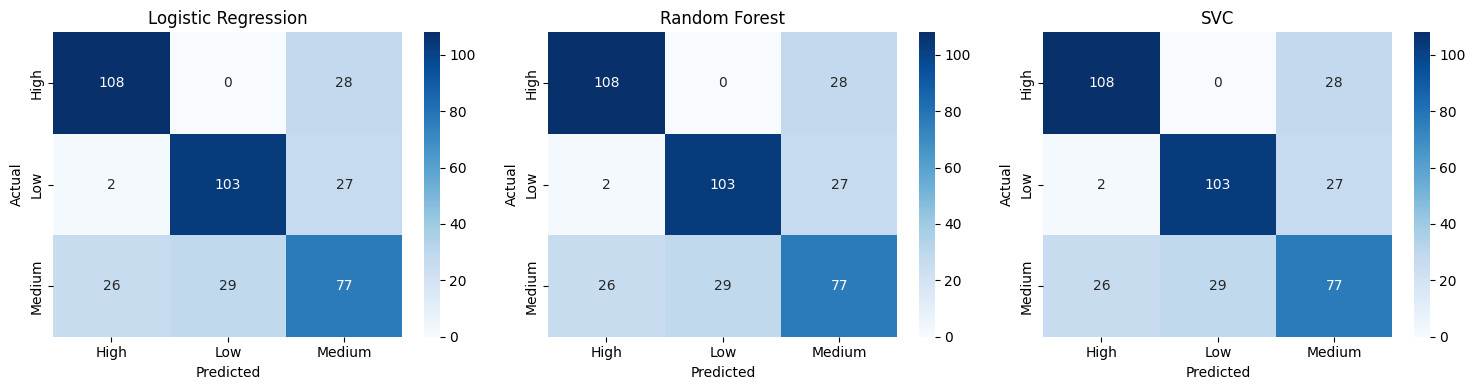

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [ ]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10]
    },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [8, 12, None],
        "model__min_samples_split": [2, 5]
    },
    "SVC": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    }
}

In [ ]:
optimized_models = {}
tuning_results = []

for name, pipeline in trained_models.items():
    grid = GridSearchCV(
        pipeline,
        param_grids[name],
        cv=5,
        scoring="f1_macro",
        n_jobs=-1
    )
    grid.fit(X_train, y_train)

    optimized_models[name] = grid.best_estimator_
    tuning_results.append({
        "Model": name,
        "CV F1-score": grid.best_score_,
        "Best params": grid.best_params_
    })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

,Model,CV F1-score
0,Logistic Regression,0.747476
1,Random Forest,0.687140
2,SVC,0.746411


In [ ]:
comparison = tuning_df[["Model", "CV F1-score"]].sort_values(
    "CV F1-score", ascending=False
)
display(comparison.round(3))

best_name = comparison.iloc[0]["Model"]
best_model = optimized_models[best_name]

print("Best model:", best_name)

,Model,CV F1-score
0,Logistic Regression,0.747
2,SVC,0.746
1,Random Forest,0.687


Best model: Logistic Regression


Accuracy : 0.757
Precision: 0.757
Recall   : 0.757
F1-score : 0.757
ROC-AUC  : 0.914

Classification Report:
              precision    recall  f1-score   support

        High       0.81      0.82      0.82       136
         Low       0.82      0.81      0.82       132
      Medium       0.64      0.64      0.64       132

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400



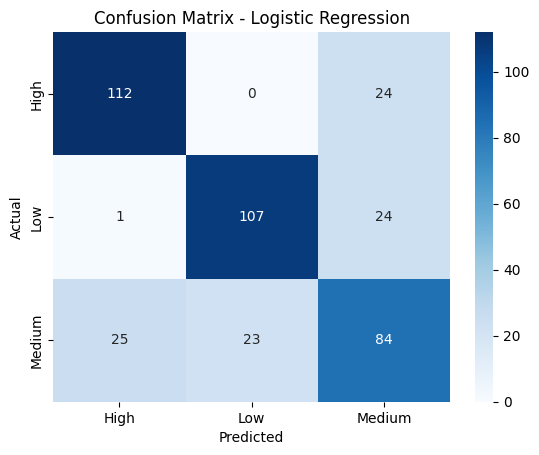

In [ ]:
y_pred = best_model.predict(X_test)

final_metrics = evaluate(best_model)
print(pd.Series(final_metrics).round(3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

In [ ]:
mask = y_test.values != y_pred

errors = X_test.loc[mask].copy()
errors["Actual"] = y_test[mask].values
errors["Predicted"] = y_pred[mask]

print("Total errors:", len(errors), "out of", len(y_test))
print("\nMost frequent confusions:")
print(errors.groupby(["Actual", "Predicted"]).size().sort_values(ascending=False))

display(errors.head(10))

Total errors: 97


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Actual,Predicted
2,22,Female,4,5.9,21.7,2.23,6.1,9.0,Moderate,3.1,9.4,86.5,Yes,Poor,No,Low,Medium
3,25,Male,1,6.9,19.7,2.35,6.4,8.8,Low,6.8,7.2,75.3,Yes,Poor,No,Medium,High
9,23,Male,1,7.8,4.9,2.15,6.3,9.9,Low,6.1,5.9,78.7,Yes,Good,No,High,Medium
11,22,Female,3,8.4,18.5,2.47,5.8,8.1,High,3.0,3.4,75.7,No,Poor,No,Medium,Low
12,22,Male,1,6.1,17.9,2.22,5.5,8.7,High,2.4,7.7,87.9,Yes,Average,No,Medium,Low
17,21,Male,5,6.5,22.5,2.38,NaN,7.9,High,6.5,8.8,84.7,No,Average,No,Medium,Low
26,21,Female,5,6.3,25.6,2.60,6.9,8.3,Moderate,4.6,6.2,84.5,No,Good,No,Medium,Low
27,22,Male,3,6.2,15.1,2.64,8.0,10.5,Low,4.3,4.8,82.1,No,Average,No,Medium,High
38,22,Female,1,8.3,14.3,2.37,7.2,7.6,Moderate,5.4,NaN,71.2,No,Average,No,Medium,Low
40,19,Female,2,6.9,19.8,2.49,3.8,6.7,High,2.8,4.5,79.5,No,Average,Yes,Medium,Low


Model saved successfully!


In [ ]:
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

joblib.dump(best_model, models_dir / "best_model.joblib")
results_df.to_csv(models_dir / "baseline_results.csv")

json.dump(final_metrics, open(models_dir / "final_metrics.json", "w"))

pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=best_model.classes_),
    index=best_model.classes_, columns=best_model.classes_
).to_csv(models_dir / "confusion_matrix.csv")